# GROUP 5 - Multimodal Information Retrieval - Assignment 2 - — End-to-End Text Video Retrieval

Contributors: Santosh Srinivas G - 2025ae05691

Pipeline: validate dataset → sample 8 frames → pretrained CLIP features → mean pooling → GRU temporal model → video-level evaluation → retrieval index → Streamlit app.

Streamlit application screenshots: https://drive.google.com/drive/u/0/folders/1B-xsA_uhu4NwdYVMPB3qyUGNSWTORDFI
Github code: 

## 1. Install dependencies
OpenCLIP supplies pretrained CLIP encoders; OpenCV reads MP4 frames; PyTorch trains the GRU; Streamlit provides the dashboard.

In [1]:
%pip install -q open_clip_torch opencv-python matplotlib scikit-learn streamlit pillow

Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'c:\Santosh\AI\BITS-Pilani\Sem3\MultiModalInformationRetrival\Assignment-2\Notebook-Code\.venv\Scripts\python.exe -m pip install --upgrade pip' command.


In [4]:
import torch
import numpy as np
import random
import os
import json
import pandas as pd

from pathlib import Path
from sklearn.model_selection import train_test_split
from IPython.display import display

# Set random seeds
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

# Check compute device
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("PyTorch version:", torch.__version__)
print("Compute device:", DEVICE)

PyTorch version: 2.14.1+cpu
Compute device: cpu


In [6]:

from pathlib import Path
import json
import random
import os
import numpy as np
import pandas as pd
import torch

from pathlib import Path

PROJECT_ROOT = Path(
    r"C:\Santosh\AI\BITS-Pilani\Sem3\MultiModalInformationRetrival\Assignment-2\Notebook-Code"
)

DATA_DIR = PROJECT_ROOT / "data"
ANNOTATION_DIR = DATA_DIR / "annotations"
VIDEO_DIR = DATA_DIR / "videos"

ARTIFACT_DIR = PROJECT_ROOT / "artifacts"
RESULTS_DIR = PROJECT_ROOT / "results"
SCREENSHOT_DIR = RESULTS_DIR / "screenshots"

# Create required directories
directories = [
    ANNOTATION_DIR,
    VIDEO_DIR,
    ARTIFACT_DIR,
    RESULTS_DIR,
    SCREENSHOT_DIR
]

for directory in directories:
    directory.mkdir(parents=True, exist_ok=True)

ANNOTATION_FILE = ANNOTATION_DIR / "MSRVTT_100.json"

print("Project:", PROJECT_ROOT)
print("Annotation file:", ANNOTATION_FILE)
print("Annotation exists:", ANNOTATION_FILE.exists())
print("Videos folder exists:", VIDEO_DIR.exists())

# Configuration
SEED = 42
NUM_FRAMES = 8
EMBEDDING_DIM = 512

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("\nProject:", PROJECT_ROOT)
print("Annotation exists:", ANNOTATION_FILE.exists())
print("Videos folder exists:", VIDEO_DIR.exists())
print("Compute device:", DEVICE)


Project: C:\Santosh\AI\BITS-Pilani\Sem3\MultiModalInformationRetrival\Assignment-2\Notebook-Code
Annotation file: C:\Santosh\AI\BITS-Pilani\Sem3\MultiModalInformationRetrival\Assignment-2\Notebook-Code\data\annotations\MSRVTT_100.json
Annotation exists: False
Videos folder exists: True

Project: C:\Santosh\AI\BITS-Pilani\Sem3\MultiModalInformationRetrival\Assignment-2\Notebook-Code
Annotation exists: False
Videos folder exists: True
Compute device: cpu


## 2. Load the existing `MSRVTT_100.json`

The JSON is expected to contain `videos` and `sentences`. Repeated caption text is retained: the requirement is two caption records per video, not necessarily two unique strings.

In [7]:
if not ANNOTATION_FILE.exists():
    raise FileNotFoundError(f"Place your existing MSRVTT_100.json at: {ANNOTATION_FILE}")
with open(ANNOTATION_FILE, encoding="utf-8") as f:
    ann = json.load(f)

videos_meta = ann.get("videos", [])
sentences = ann.get("sentences", [])
if not videos_meta or not sentences:
    raise ValueError(f"Expected non-empty 'videos' and 'sentences'. Found keys: {list(ann.keys())}")

meta_by_id = {str(v["video_id"]): v for v in videos_meta}
rows = []
for s in sentences:
    vid = str(s["video_id"])
    meta = meta_by_id.get(vid, {})
    rows.append({
        "video_id": vid,
        "caption": str(s["caption"]),
        "category": meta.get("category", meta.get("category_id", -1)),
        "video_path": str(VIDEO_DIR / f"{vid}.mp4")
    })
df = pd.DataFrame(rows)
video_ids = sorted(df.video_id.unique())
print("Video metadata records:", len(videos_meta))
print("Caption records:", len(df))
print("Unique caption video IDs:", len(video_ids))
display(df.head())

Video metadata records: 100
Caption records: 200
Unique caption video IDs: 100


,video_id,caption,category,video_path
0,video1127,a girl dances and sings in various outfits and...,6,C:\Santosh\AI\BITS-Pilani\Sem3\MultiModalInfor...
1,video1127,a lady in red is dancing and singing,6,C:\Santosh\AI\BITS-Pilani\Sem3\MultiModalInfor...
2,video113,the woman in black dress interview with two ma...,4,C:\Santosh\AI\BITS-Pilani\Sem3\MultiModalInfor...
3,video113,a narrator explains what accomplishments congr...,4,C:\Santosh\AI\BITS-Pilani\Sem3\MultiModalInfor...
4,video1371,a car falls into a hole just before the finish...,9,C:\Santosh\AI\BITS-Pilani\Sem3\MultiModalInfor...


### 2.1 Validate assignment requirements
Check 100 videos, 2 caption records each, category distribution when category labels exist, and availability of all MP4 files.

In [8]:
assert len(video_ids) == 100, f"Expected 100 videos, got {len(video_ids)}"
counts = df.groupby("video_id").size()
assert (counts == 2).all(), f"Expected 2 caption rows/video. Distribution:\n{counts.value_counts()}"
cat_df = df[["video_id", "category"]].drop_duplicates()
if not (cat_df.category.astype(str) == "-1").all():
    per_cat = cat_df.groupby("category").video_id.nunique()
    print("Videos per category:\n", per_cat)
    assert len(per_cat) == 20 and (per_cat == 5).all()
# Resolve filenames case-insensitively if needed; do not rename any file.
available = {p.stem.lower(): p for p in VIDEO_DIR.glob("*.mp4")}
resolved = []
for vid in df.video_id:
    expected = VIDEO_DIR / f"{vid}.mp4"
    actual = expected if expected.exists() else available.get(vid.lower())
    resolved.append(str(actual.resolve()) if actual else str(expected))
df["video_path"] = resolved
missing = sorted(set(p for p in df.video_path if not Path(p).exists()))
assert not missing, f"Missing {len(missing)} videos. Examples: {missing[:5]}"
print("VALIDATION PASSED: 100 videos, 200 captions, video files found.")

Videos per category:
 category
0     5
1     5
2     5
3     5
4     5
5     5
6     5
7     5
8     5
9     5
10    5
11    5
12    5
13    5
14    5
15    5
16    5
17    5
18    5
19    5
Name: video_id, dtype: int64
VALIDATION PASSED: 100 videos, 200 captions, video files found.


## 3. Uniformly sample 8 frames per video

Eight positions are selected evenly between the first and last frame. The sequence order is preserved for the GRU. A limitation is that short actions may occur between sampled positions.

Frame tensor shape: (8, 224, 224, 3)


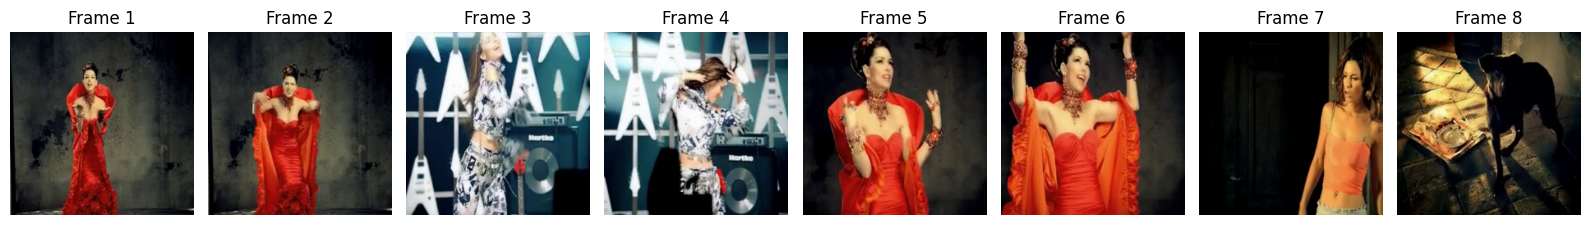

In [9]:
def sample_video_frames(path, n_frames=NUM_FRAMES, image_size=224):
    cap = cv2.VideoCapture(str(path))
    if not cap.isOpened(): raise RuntimeError(f"Cannot open video: {path}")
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if total <= 0:
        cap.release()
        raise RuntimeError(f"No frames found: {path}")
    indices = np.linspace(0, total-1, n_frames, dtype=int)
    frames = []
    for idx in indices:
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx))
        ok, frame = cap.read()
        if ok:
            frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            frames.append(cv2.resize(frame, (image_size, image_size)))
    cap.release()
    if not frames: raise RuntimeError(f"Could not decode: {path}")
    while len(frames) < n_frames: frames.append(frames[-1].copy())
    return np.stack(frames[:n_frames])

preview = sample_video_frames(df.iloc[0].video_path)
print("Frame tensor shape:", preview.shape)
fig, axes = plt.subplots(1, NUM_FRAMES, figsize=(16,3))
for i, ax in enumerate(axes):
    ax.imshow(preview[i]); ax.set_title(f"Frame {i+1}"); ax.axis("off")
plt.tight_layout()

## 4. Load pretrained CLIP

CLIP image and text encoders map images and language into a shared 512-dimensional semantic space. We use pretrained ViT-B/32 weights and keep CLIP frozen.

In [10]:
CLIP_MODEL_NAME = "ViT-B-32"
CLIP_PRETRAINED = "laion2b_s34b_b79k"
if (CLIP_MODEL_NAME, CLIP_PRETRAINED) not in open_clip.list_pretrained():
    print("Available ViT-B-32 checkpoints:")
    print([x for x in open_clip.list_pretrained() if x[0] == CLIP_MODEL_NAME])
    raise ValueError("Update CLIP_PRETRAINED to an available checkpoint.")
clip_model, _, preprocess = open_clip.create_model_and_transforms(
    CLIP_MODEL_NAME, pretrained=CLIP_PRETRAINED)
tokenizer = open_clip.get_tokenizer(CLIP_MODEL_NAME)
clip_model = clip_model.to(DEVICE).eval()
print("CLIP ready on", DEVICE)

CLIP ready on cpu


## 5. Extract frame embeddings and create the mean-pooling baseline

For each video, CLIP produces `(8, 512)`. Averaging over the 8 frames produces `(512,)`. L2 normalization scales the result to length 1. For normalized text and video vectors, dot product equals cosine similarity.

In [11]:
@torch.no_grad()
def encode_frames(frames):
    batch = torch.stack([preprocess(Image.fromarray(x)) for x in frames]).to(DEVICE)
    z = clip_model.encode_image(batch).float()
    return F.normalize(z, dim=-1).cpu().numpy()

frame_embeddings, mean_embeddings = {}, {}
for i, vid in enumerate(video_ids, 1):
    path = df.loc[df.video_id == vid, "video_path"].iloc[0]
    seq = encode_frames(sample_video_frames(path))  # (8,512)
    frame_embeddings[vid] = seq
    pooled = torch.tensor(seq.mean(axis=0), dtype=torch.float32)
    mean_embeddings[vid] = F.normalize(pooled, dim=0).numpy()
    if i % 10 == 0: print(f"Encoded {i}/{len(video_ids)} videos")
print("Per-video sequence:", frame_embeddings[video_ids[0]].shape)
print("Mean gallery:", np.stack([mean_embeddings[v] for v in video_ids]).shape)
np.savez_compressed(ARTIFACT_DIR/"clip_video_features.npz",
    video_ids=np.array(video_ids),
    frame_features=np.stack([frame_embeddings[v] for v in video_ids]),
    mean_features=np.stack([mean_embeddings[v] for v in video_ids]))

Encoded 10/100 videos
Encoded 20/100 videos
Encoded 30/100 videos
Encoded 40/100 videos
Encoded 50/100 videos
Encoded 60/100 videos
Encoded 70/100 videos
Encoded 80/100 videos
Encoded 90/100 videos
Encoded 100/100 videos
Per-video sequence: (8, 512)
Mean gallery: (100, 512)


## 6. Encode captions and split by video ID

The train/test split is made by video ID, not caption row. Thus, both captions from a video stay in the same partition. This prevents the GRU from training on one caption for a video and being evaluated on another caption for that same video.

In [12]:
def encode_texts(texts, batch_size=64):
    chunks = []
    with torch.no_grad():
        for start in range(0, len(texts), batch_size):
            toks = tokenizer(texts[start:start+batch_size]).to(DEVICE)
            z = clip_model.encode_text(toks).float()
            chunks.append(F.normalize(z, dim=-1).cpu().numpy())
    return np.vstack(chunks)

df = df.copy()
df["caption_order"] = df.groupby("video_id").cumcount()
text_vectors = encode_texts(df.caption.tolist())
df["text_embedding"] = list(text_vectors)

train_ids, test_ids = train_test_split(video_ids, test_size=0.20, random_state=SEED)
train_ids, test_ids = sorted(train_ids), sorted(test_ids)
print("Training videos:", len(train_ids), "| held-out test videos:", len(test_ids))

Training videos: 80 | held-out test videos: 20


## 7. Train the temporal GRU

Input shape: `(batch, 8, 512)`. The GRU reads the ordered frame sequence and maps its final hidden state to a normalized 512-D video vector. Symmetric contrastive loss aligns matching video/text pairs in both video-to-text and text-to-video directions. CLIP remains frozen; only the GRU and projection layer train.

Epoch 10/100: 2.9889
Epoch 20/100: 0.8087
Epoch 30/100: 0.3015
Epoch 40/100: 0.1389
Epoch 50/100: 0.0861
Epoch 60/100: 0.0629
Epoch 70/100: 0.0505
Epoch 80/100: 0.0430
Epoch 90/100: 0.0377
Epoch 100/100: 0.0338


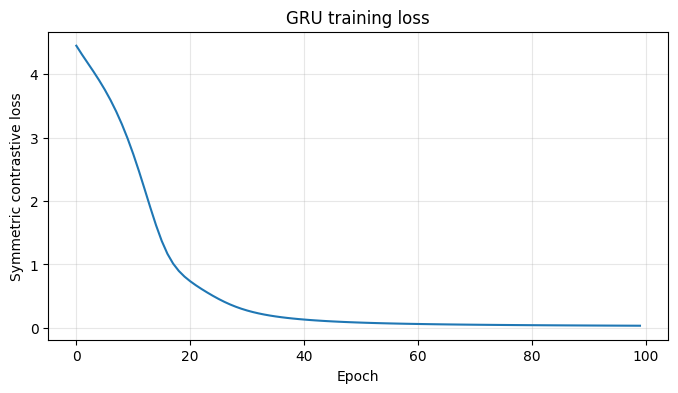

In [13]:
class TemporalGRU(nn.Module):
    def __init__(self, input_dim=512, hidden_dim=512, output_dim=512):
        super().__init__()
        self.gru = nn.GRU(input_dim, hidden_dim, batch_first=True)
        self.projection = nn.Linear(hidden_dim, output_dim)
    def forward(self, x):
        _, h = self.gru(x)
        return F.normalize(self.projection(h[-1]), dim=-1)

gru_model = TemporalGRU().to(DEVICE)
train_text_map = (
    df[df.video_id.isin(train_ids)]
    .sort_values(["video_id","caption_order"])
    .groupby("video_id")["text_embedding"].first().to_dict()
)
x_train = torch.tensor(np.stack([frame_embeddings[v] for v in train_ids]),
                       dtype=torch.float32, device=DEVICE)
t_train = torch.tensor(np.stack([train_text_map[v] for v in train_ids]),
                       dtype=torch.float32, device=DEVICE)
optimizer = torch.optim.AdamW(gru_model.parameters(), lr=2e-4, weight_decay=1e-4)
temperature, epochs = 0.07, 100
loss_history = []
for epoch in range(epochs):
    gru_model.train(); optimizer.zero_grad()
    v = gru_model(x_train)
    logits = (v @ t_train.T) / temperature
    labels = torch.arange(len(train_ids), device=DEVICE)
    loss = (F.cross_entropy(logits, labels) + F.cross_entropy(logits.T, labels))/2
    loss.backward(); optimizer.step()
    loss_history.append(float(loss.item()))
    if (epoch+1) % 10 == 0: print(f"Epoch {epoch+1}/{epochs}: {loss.item():.4f}")
plt.figure(figsize=(8,4)); plt.plot(loss_history)
plt.xlabel("Epoch"); plt.ylabel("Symmetric contrastive loss")
plt.title("GRU training loss"); plt.grid(True, alpha=.3); plt.show()
torch.save(gru_model.state_dict(), ARTIFACT_DIR/"temporal_gru.pt")

## 8. Create GRU vectors and evaluate held-out video retrieval

The test gallery contains only held-out videos. Each held-out video is queried using its second caption record. The same queries and gallery are used for both mean pooling and GRU.

In [14]:
gru_model.eval()
with torch.no_grad():
    all_seq = torch.tensor(np.stack([frame_embeddings[v] for v in video_ids]),
                           dtype=torch.float32, device=DEVICE)
    gru_matrix = gru_model(all_seq).cpu().numpy().astype("float32")
gru_embeddings = {v: gru_matrix[i] for i,v in enumerate(video_ids)}

def evaluate_retrieval(query_df, candidate_ids, gallery, ks=(1,5,10)):
    mat = np.stack([gallery[v] for v in candidate_ids]).astype("float32")
    mat /= np.maximum(np.linalg.norm(mat, axis=1, keepdims=True), 1e-12)
    ranks = []
    for row in query_df.itertuples():
        q = np.asarray(row.text_embedding, dtype="float32")
        q = q / max(np.linalg.norm(q), 1e-12)
        order = np.argsort(-(mat @ q))
        ranked_ids = [candidate_ids[j] for j in order]
        ranks.append(ranked_ids.index(row.video_id)+1)
    ranks = np.asarray(ranks)
    result = {}
    for k in ks:
        result[f"Recall@{k}"] = float(np.mean(ranks <= k))
        result[f"Precision@{k}"] = result[f"Recall@{k}"] / k
    result["MRR"] = float(np.mean(1/ranks))
    result["Mean_Rank"] = float(np.mean(ranks))
    result["Median_Rank"] = float(np.median(ranks))
    return result, ranks

test_queries = df[(df.video_id.isin(test_ids)) & (df.caption_order == 1)].reset_index(drop=True)
mean_gallery = {v: mean_embeddings[v] for v in test_ids}
gru_gallery = {v: gru_embeddings[v] for v in test_ids}
mean_metrics, mean_ranks = evaluate_retrieval(test_queries, test_ids, mean_gallery)
gru_metrics, gru_ranks = evaluate_retrieval(test_queries, test_ids, gru_gallery)
metrics_df = pd.DataFrame([
    {"Model":"Mean pooling", **mean_metrics},
    {"Model":"Temporal GRU", **gru_metrics}
])
display(metrics_df.round(4))
metrics_df.to_csv(RESULTS_DIR/"video_level_test_metrics.csv", index=False)

,Model,Recall@1,Precision@1,Recall@5,Precision@5,Recall@10,Precision@10,MRR,Mean_Rank,Median_Rank
0,Mean pooling,0.6,0.6,0.95,0.19,1.00,0.100,0.7671,1.80,1.0
1,Temporal GRU,0.1,0.1,0.75,0.15,0.85,0.085,0.3668,5.55,3.0


## 9. Compare and interpret the models

Do not assume that GRU must outperform mean pooling. With only 80 training videos and 8 sampled frames, CLIP's pretrained frame features may already be strong. A trainable temporal aggregator may need more data or richer motion features to show an advantage.

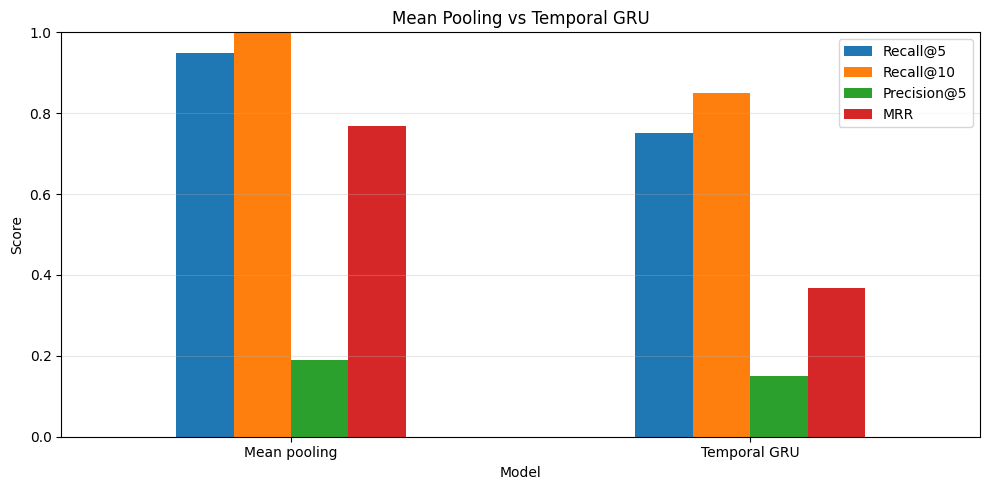

Best by MRR: Mean pooling


In [15]:
ax = metrics_df.set_index("Model")[["Recall@5","Recall@10","Precision@5","MRR"]].plot(
    kind="bar", figsize=(10,5), ylim=(0,1), title="Mean Pooling vs Temporal GRU")
ax.set_ylabel("Score"); ax.grid(axis="y", alpha=.3)
plt.xticks(rotation=0); plt.tight_layout(); plt.show()
print("Best by MRR:", metrics_df.sort_values("MRR", ascending=False).iloc[0]["Model"])

## 10. Save retrieval artifacts
The app needs both video-vector variants, video IDs and paths, plus the CLIP checkpoint metadata.

In [16]:
np.savez_compressed(ARTIFACT_DIR/"retrieval_index.npz",
    video_ids=np.array(video_ids),
    video_paths=np.array([df.loc[df.video_id==v,"video_path"].iloc[0] for v in video_ids]),
    mean_embeddings=np.stack([mean_embeddings[v] for v in video_ids]).astype("float32"),
    gru_embeddings=np.stack([gru_embeddings[v] for v in video_ids]).astype("float32"))
with open(ARTIFACT_DIR/"model_config.json","w",encoding="utf-8") as f:
    json.dump({"clip_model":CLIP_MODEL_NAME,"clip_pretrained":CLIP_PRETRAINED,
               "num_frames":NUM_FRAMES,"embedding_dim":EMBEDDING_DIM},f,indent=2)
print("Artifacts saved to:", ARTIFACT_DIR)

Artifacts saved to: C:\Santosh\AI\BITS-Pilani\Sem3\MultiModalInformationRetrival\Assignment-2\Notebook-Code\artifacts


## 11. Generate Streamlit dashboard (`app.py`)

The dashboard supports natural-language input, model selection, Top-K selection, playable video results and similarity scores.

In [17]:
app_source = 'import json\nfrom pathlib import Path\nimport numpy as np\nimport streamlit as st\nimport torch\nimport torch.nn.functional as F\nimport open_clip\n\nROOT = Path(__file__).resolve().parent\nART = ROOT / "artifacts"\nDEVICE = "cuda" if torch.cuda.is_available() else "cpu"\nst.set_page_config(page_title="MSR-VTT Video Retrieval", layout="wide")\nst.title("Natural-Language Video Retrieval")\nst.caption("MSR-VTT · CLIP shared embedding space")\n\n@st.cache_resource\ndef load_models():\n    with open(ART/"model_config.json", encoding="utf-8") as f:\n        cfg = json.load(f)\n    idx = np.load(ART/"retrieval_index.npz", allow_pickle=True)\n    model, _, _ = open_clip.create_model_and_transforms(\n        cfg["clip_model"], pretrained=cfg["clip_pretrained"])\n    tokenizer = open_clip.get_tokenizer(cfg["clip_model"])\n    return idx, model.to(DEVICE).eval(), tokenizer\n\ntry:\n    index, clip_model, tokenizer = load_models()\nexcept Exception as e:\n    st.error(f"Run all notebook cells through artifact creation first. Details: {e}")\n    st.stop()\n\nquery = st.text_input("Natural-language query", placeholder="A person is playing guitar")\nmethod = st.selectbox("Video representation", ["Mean Pooling", "Temporal GRU"])\ntop_k = st.slider("Top-K", 1, 10, 5)\nif st.button("Search", type="primary") and query.strip():\n    with torch.no_grad():\n        tok = tokenizer([query]).to(DEVICE)\n        q = F.normalize(clip_model.encode_text(tok).float(), dim=-1).cpu().numpy()[0]\n    key = "mean_embeddings" if method == "Mean Pooling" else "gru_embeddings"\n    gallery = index[key].astype("float32")\n    gallery /= np.maximum(np.linalg.norm(gallery, axis=1, keepdims=True), 1e-12)\n    scores = gallery @ q\n    order = np.argsort(-scores)[:top_k]\n    st.subheader(f"Top {top_k} results — {method}")\n    for rank, i in enumerate(order, 1):\n        vid, path = str(index["video_ids"][i]), str(index["video_paths"][i])\n        with st.container(border=True):\n            c1,c2 = st.columns([1,2])\n            with c1:\n                if Path(path).exists(): st.video(path)\n                else: st.warning(f"Video missing: {path}")\n            with c2:\n                st.markdown(f"**Rank {rank}: {vid}**")\n                st.metric("Cosine similarity", f"{float(scores[i]):.4f}")\nelse:\n    st.info("Enter a query and click Search.")\n'
app_path = PROJECT_ROOT/'app.py'
app_path.write_text(app_source, encoding='utf-8')
print('Created:', app_path)

Created: C:\Santosh\AI\BITS-Pilani\Sem3\MultiModalInformationRetrival\Assignment-2\Notebook-Code\app.py


## 12. Run the dashboard and capture screenshots


```powershell
streamlit run app.py
```
Captured screenshots under `results/screenshots/`. 